# 03 · Exploratory Data Analysis

**Stage 3.** Hypothesis-driven, not open-ended (STRUCTURE.md §3): one section per branch of the
Stage 0 issue tree, every chart tied to a ghost-deck exhibit, every finding carrying an **Action
Title** and a written **So What / Implication**. No orphan charts.

```
Why is attrition concentrated where it is, and which parts of it can HR act on?
├── A. Fixed traits            Age, Gender, MaritalStatus, Education, EducationField
├── B. Role & structure        Department, JobRole, JobLevel, BusinessTravel
├── C. Compensation & reward   MonthlyIncome, StockOptionLevel, PercentSalaryHike, PerformanceRating
├── D. Workload & friction     OverTime, DistanceFromHome, TrainingTimesLastYear
├── E. Tenure & trajectory     YearsAtCompany, TotalWorkingYears, YearsInCurrentRole,
│                              YearsSinceLastPromotion, YearsWithCurrManager, NumCompaniesWorked
├── F. Engagement  ⚠ quarantined to Scope 2 (DOCS §3B leakage risk)
└── Z. Non-features  ⚠ the placebo control convicted in 02_cleaning §2.1
```

**Actionability split, declared before looking:** branches B/C/D/F contain levers HR can pull;
branch A does not. Findings in A are reported for targeting and fairness purposes only, never as
recommendations.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

SRC_NAME = "WA_Fn-UseC_-HR-Employee-Attrition.csv"
ROOT = Path.cwd() if (Path.cwd() / SRC_NAME).exists() else Path.cwd().parent
PROC, REP, FIG = ROOT / "data" / "processed", ROOT / "reports", ROOT / "reports" / "figures"

# --- DESIGN.md palette + rcParams, defined inline (no src/ import, per the plan) ---
NAVY, BLUE, TEAL, CYAN = "#051C2C", "#2251FF", "#00857C", "#00A9F4"
AMBER, SLATE, GREY, GRID = "#C1841C", "#7F93A6", "#9FADB8", "#E9ECEF"
CAT_ORDER = [BLUE, TEAL, AMBER, CYAN, SLATE]
# Semantic mapping for this project (fixed in IMPLEMENTATION_PLAN.md S7.2):
LEAVER, STAYER, PLACEBO, MARKER = BLUE, TEAL, GREY, AMBER

import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 160, "figure.facecolor": "white",
    "savefig.facecolor": "white", "savefig.bbox": "tight",
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica Neue", "DejaVu Sans"],
    "font.size": 9, "text.color": NAVY,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": NAVY, "axes.titlepad": 10,
    "axes.labelsize": 9, "axes.labelcolor": SLATE, "axes.edgecolor": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.8,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.7,
    "xtick.color": SLATE, "ytick.color": SLATE, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "legend.fontsize": 8.5,
})


def figsave(fig, name):
    """Save an exhibit to reports/figures/ under its exhibit id."""
    FIG.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIG / f"{name}.png")
    print("saved:", name + ".png")


df = pd.read_parquet(PROC / "hr_clean.parquet")
contract = pd.read_csv(PROC / "_column_contract.csv")
y = df.Attrition_flag
BASE = y.mean()
PLACEBOS = contract.loc[contract.role == "placebo", "column"].tolist()
BR = dict(zip(contract.column, contract.branch))

print(f"{df.shape[0]:,} employees x {df.shape[1]} columns")
print(f"attrition base rate {BASE:.1%} ({int(y.sum())} leavers)")
print(f"placebo columns: {PLACEBOS}")

1,470 employees x 33 columns
attrition base rate 16.1% (237 leavers)
placebo columns: ['DailyRate', 'HourlyRate', 'MonthlyRate']


## 3.1 First-pass profile

`ydata-profiling` is optional in this project (it would break a clone running on the pinned
requirements), so the profile is built manually. It has one job here: confirm the shape facts the
cleaning decisions rest on.

In [2]:
num = contract[(contract.scale == "numeric") & (contract.role == "feature")].column.tolist()
prof = pd.DataFrame({
    "n_unique": df[num].nunique(),
    "median": df[num].median().round(1),
    "IQR": (df[num].quantile(.75) - df[num].quantile(.25)).round(1),
    "skew": df[num].skew().round(2),
    "zeros_%": (df[num] == 0).mean().mul(100).round(1),
}).sort_values("skew", ascending=False)
print(prof.to_string())
print("\nScale disparity across the numeric block:")
print(f"  smallest sd {df[num].std().min():,.1f}  ({df[num].std().idxmin()})")
print(f"  largest  sd {df[num].std().max():,.1f}  ({df[num].std().idxmax()})")
print("  -> standardisation is mandatory for the logistic/SVM path (fit inside the Pipeline).")

                         n_unique  median     IQR  skew  zeros_%
YearsSinceLastPromotion        16     1.0     3.0  1.98     39.5
PerformanceRating               2     3.0     0.0  1.92      0.0
YearsAtCompany                 37     5.0     6.0  1.76      3.0
MonthlyIncome                1349  4919.0  5468.0  1.37      0.0
TotalWorkingYears              40    10.0     9.0  1.12      0.7
NumCompaniesWorked             10     2.0     3.0  1.03     13.4
DistanceFromHome               29     7.0    12.0  0.96      0.0
YearsInCurrentRole             19     3.0     5.0  0.92     16.6
YearsWithCurrManager           18     3.0     5.0  0.83     17.9
PercentSalaryHike              15    14.0     6.0  0.82      0.0
TrainingTimesLastYear           7     3.0     1.0  0.55      3.7
Age                            43    36.0    13.0  0.41      0.0

Scale disparity across the numeric block:
  smallest sd 0.4  (PerformanceRating)
  largest  sd 4,708.0  (MonthlyIncome)
  -> standardisation is mandatory 

> **So What:** four tenure fields are strongly right-skewed with heavy zero mass, so **every
> group comparison in this project reports medians, not means** (`DOCS` §5). The 6,000-fold spread
> in standard deviation confirms scaling belongs inside the modelling Pipeline.

## 3.2 The class balance, and the trap it sets

The single most important number for how this project is evaluated.

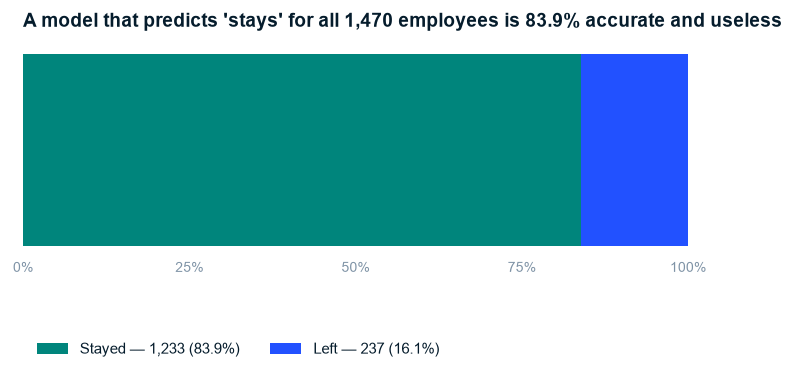

majority-class accuracy : 83.9%
majority-class recall   : 0.0%  (catches 0 of 237 leavers)
majority-class PR-AUC   : 0.161  (= the base rate; this is the floor to beat)


In [3]:
fig, ax = plt.subplots(figsize=(6.6, 2.1))
ax.barh([0], [1 - BASE], color=STAYER, height=.55, label=f"Stayed — {int((1-y).sum()):,} (83.9%)")
ax.barh([0], [BASE], left=[1 - BASE], color=LEAVER, height=.55, label=f"Left — {int(y.sum())} (16.1%)")
ax.set_xlim(0, 1); ax.set_yticks([]); ax.set_xticks(np.arange(0, 1.01, .25))
ax.set_xticklabels([f"{v:.0%}" for v in np.arange(0, 1.01, .25)])
ax.grid(False); ax.spines["left"].set_visible(False); ax.spines["bottom"].set_visible(False)
ax.legend(loc="lower left", bbox_to_anchor=(0, -.55), ncol=2)
ax.set_title("A model that predicts 'stays' for all 1,470 employees is 83.9% accurate and useless",
             loc="left")
plt.show()

print(f"majority-class accuracy : {1 - BASE:.1%}")
print(f"majority-class recall   : 0.0%  (catches 0 of {int(y.sum())} leavers)")
print(f"majority-class PR-AUC   : {BASE:.3f}  (= the base rate; this is the floor to beat)")

> **So What:** accuracy is disqualified as a metric for this project. Primary metrics are
> **PR-AUC** (floor = 0.161) and **recall on leavers**; ROC-AUC is reported for comparability only.
> Every split and fold is stratified.

## 3.3 Correlation structure — with the placebo block boxed off

Spearman throughout (skewed numerics, ordinal codes). The three placebo columns are drawn inside a
box so their independence from everything else is visible rather than asserted.

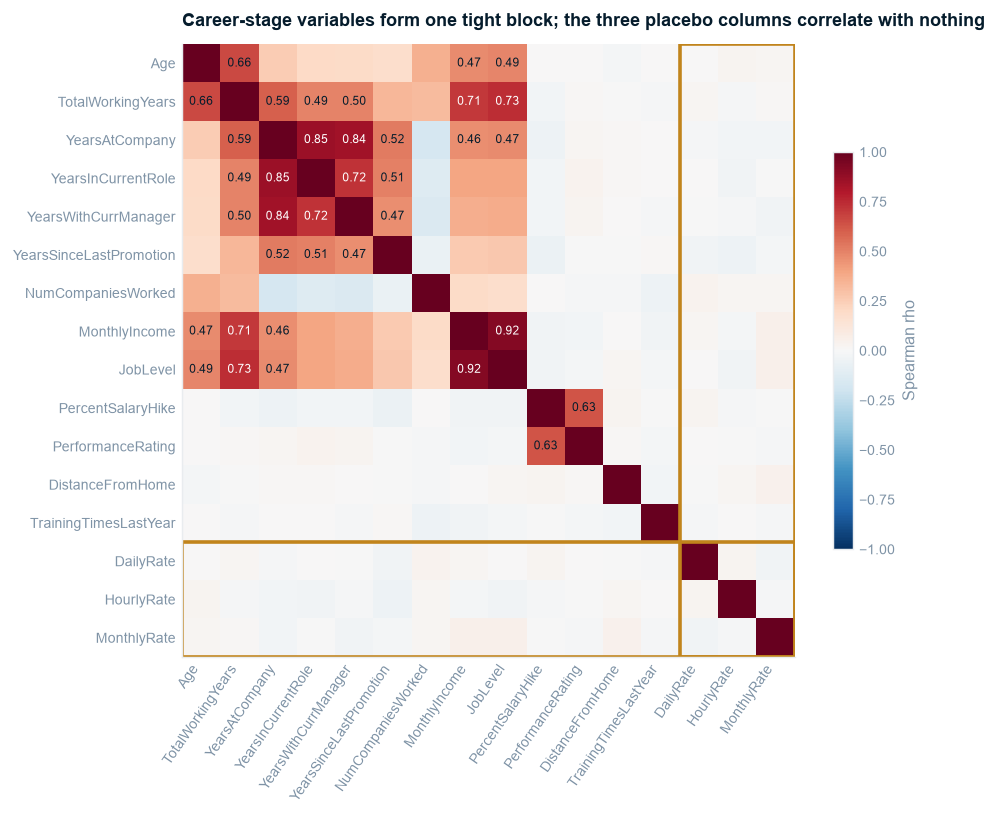

Max |rho| the placebo block achieves against any real column: 0.054


In [4]:
ordered = [c for c in ["Age", "TotalWorkingYears", "YearsAtCompany", "YearsInCurrentRole",
                       "YearsWithCurrManager", "YearsSinceLastPromotion", "NumCompaniesWorked",
                       "MonthlyIncome", "JobLevel", "PercentSalaryHike", "PerformanceRating",
                       "DistanceFromHome", "TrainingTimesLastYear"] + PLACEBOS]
cm = df[ordered].corr(method="spearman")

fig, ax = plt.subplots(figsize=(7.6, 6.4))
im = ax.imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(ordered))); ax.set_xticklabels(ordered, rotation=55, ha="right", fontsize=7.5)
ax.set_yticks(range(len(ordered))); ax.set_yticklabels(ordered, fontsize=7.5)
ax.grid(False)
for i in range(len(ordered)):
    for j in range(len(ordered)):
        v = cm.iloc[i, j]
        if i != j and abs(v) >= .45:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5,
                    color="white" if abs(v) > .7 else NAVY)
k = len(ordered) - len(PLACEBOS)
ax.add_patch(plt.Rectangle((k - .5, -.5), len(PLACEBOS), len(ordered), fill=False,
                           edgecolor=MARKER, lw=2))
ax.add_patch(plt.Rectangle((-.5, k - .5), len(ordered), len(PLACEBOS), fill=False,
                           edgecolor=MARKER, lw=2))
ax.set_title("Career-stage variables form one tight block; the three placebo columns correlate with nothing",
             loc="left", fontsize=10)
fig.colorbar(im, ax=ax, shrink=.62, label="Spearman rho")
plt.show()

print("Max |rho| the placebo block achieves against any real column: "
      f"{cm.loc[PLACEBOS, [c for c in ordered if c not in PLACEBOS]].abs().to_numpy().max():.3f}")

> **So What:** the amber box is a picture of six columns' worth of nothing. Everything outside it
> shows structure — most of it one latent factor (career stage) expressed through
> `Age`/`TotalWorkingYears`/`JobLevel`/`MonthlyIncome`/tenure.
>
> **Implication:** those five cannot be interpreted as independent effects. The multivariate model
> in Stage 5a must report them as a block and disclose VIF.

## 3.4 Branch B + E — attrition is an early-tenure, entry-level phenomenon

Rates with **Wilson 95% intervals**, because several of these groups are small and a bare
percentage on n = 80 invites over-reading.

In [5]:
def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return (max(0, c - h), min(1, c + h))


def rate_table(col, order=None):
    g = df.groupby(col, observed=True).Attrition_flag.agg(["sum", "size"])
    if order is not None:
        g = g.reindex(order)
    g.columns = ["leavers", "n"]
    g["rate"] = g.leavers / g.n
    ci = [wilson(int(k), int(n)) for k, n in zip(g.leavers, g.n)]
    g["lo"], g["hi"] = [c[0] for c in ci], [c[1] for c in ci]
    return g


tenure_bins = pd.cut(df.YearsAtCompany, [-1, 1, 2, 5, 10, 100],
                     labels=["0–1 yr", "2 yrs", "3–5 yrs", "6–10 yrs", "10+ yrs"])
t_ten = rate_table(tenure_bins.rename("tenure_band"))
t_lvl = rate_table("JobLevel")
print("Tenure band:\n", t_ten.round(3).to_string(), "\n")
print("Job level:\n", t_lvl.round(3).to_string())

Tenure band:
              leavers    n   rate     lo     hi
tenure_band                                   
0–1 yr            75  215  0.349  0.288  0.415
2 yrs             27  127  0.213  0.150  0.292
3–5 yrs           60  434  0.138  0.109  0.174
6–10 yrs          55  448  0.123  0.096  0.156
10+ yrs           20  246  0.081  0.053  0.122 

Job level:
           leavers    n   rate     lo     hi
JobLevel                                   
1             143  543  0.263  0.228  0.302
2              52  534  0.097  0.075  0.125
3              32  218  0.147  0.106  0.200
4               5  106  0.047  0.020  0.106
5               5   69  0.072  0.031  0.159


saved: ex05_tenure_level.png


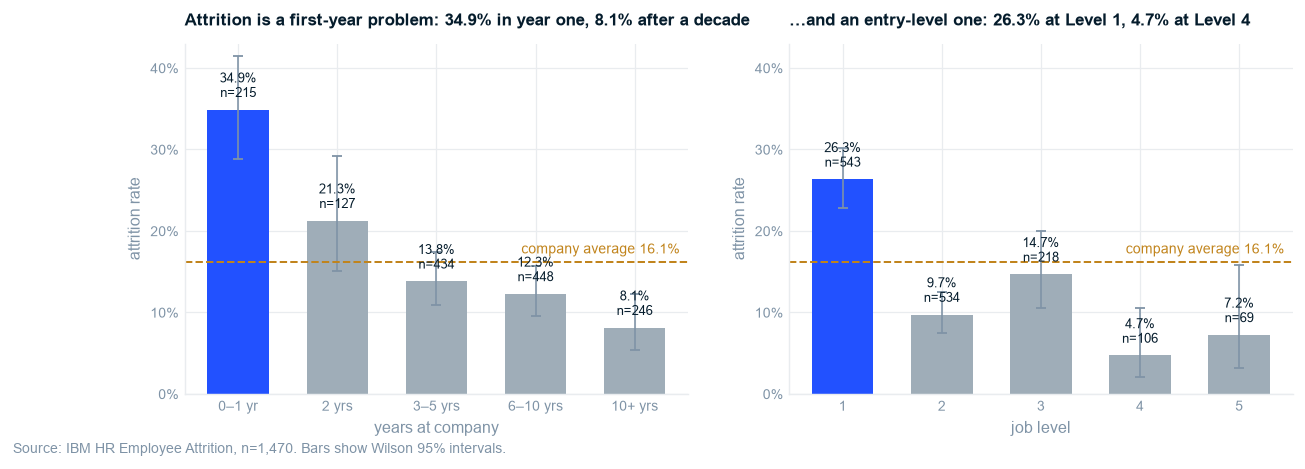

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, t, xlabel, title in [
    (axes[0], t_ten, "years at company", "Attrition is a first-year problem: 34.9% in year one, 8.1% after a decade"),
    (axes[1], t_lvl, "job level", "…and an entry-level one: 26.3% at Level 1, 4.7% at Level 4"),
]:
    x = np.arange(len(t))
    cols = [LEAVER if r == t.rate.max() else GREY for r in t.rate]
    ax.bar(x, t.rate, color=cols, width=.62)
    ax.errorbar(x, t.rate, yerr=[t.rate - t.lo, t.hi - t.rate], fmt="none", ecolor=SLATE,
                elinewidth=.9, capsize=3)
    ax.axhline(BASE, color=MARKER, ls="--", lw=1.1)
    ax.annotate(f"company average {BASE:.1%}", xy=(len(t) - .55, BASE), xytext=(0, 5),
                textcoords="offset points", ha="right", color=MARKER, fontsize=7.5)
    ax.set_xticks(x); ax.set_xticklabels([str(i) for i in t.index], fontsize=8)
    ax.set_ylim(0, .43); ax.set_yticks(np.arange(0, .41, .1))
    ax.set_yticklabels([f"{v:.0%}" for v in np.arange(0, .41, .1)])
    ax.set_xlabel(xlabel); ax.set_ylabel("attrition rate")
    ax.set_title(title, loc="left", fontsize=9.5)
    for xi, (r, n) in enumerate(zip(t.rate, t.n)):
        ax.annotate(f"{r:.1%}\nn={n:,}", xy=(xi, r), xytext=(0, 7), textcoords="offset points",
                    ha="center", fontsize=7, color=NAVY)
fig.text(0.005, -0.02, "Source: IBM HR Employee Attrition, n=1,470. Bars show Wilson 95% intervals.",
         ha="left", fontsize=7.5, color=SLATE)
figsave(fig, "ex05_tenure_level")
plt.show()

> **So What:** 143 of 237 leavers (60%) sit in Job Level 1, and 162 of them (68%) have five
> years' tenure or less. Attrition here is not a company-wide condition — it is concentrated in a
> cohort that can be named, counted, and targeted.
>
> **Implication:** a retention budget spread evenly across 1,470 employees is spread across the
> wrong people. The early-tenure Level-1 cohort is where any intervention has to land.

## 3.5 Branch C vs B — the pay finding, and why it dissolves

`DOCS` §2 reports leavers earning a median 3,202 against stayers' 5,204 and treats it as evidence
that underpayment drives attrition. `02_cleaning` §2.4 showed `MonthlyIncome` is 90% determined by
`JobLevel`. This exhibit shows the two readings side by side.

saved: ex04_pay_confound.png


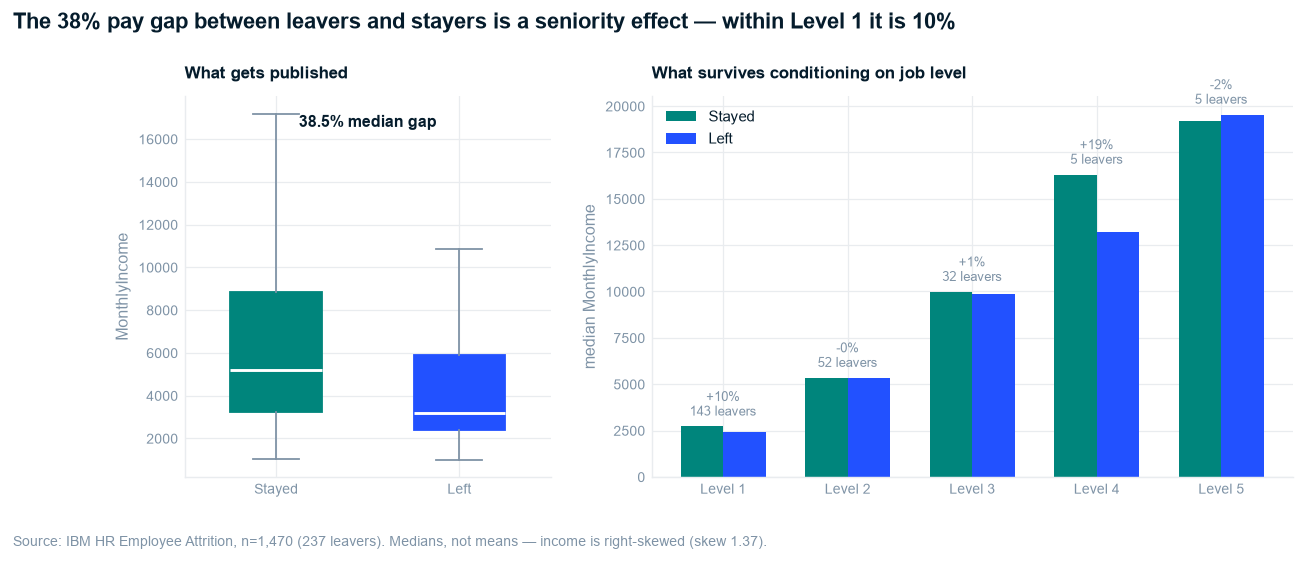

within-level gap %: {'L1': np.float64(10.4), 'L2': np.float64(-0.2), 'L3': np.float64(1.0), 'L4': np.float64(19.1), 'L5': np.float64(-1.8)}


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8),
                         gridspec_kw={"width_ratios": [1, 1.75]})

# left - the unconditional comparison
ax = axes[0]
data = [df.loc[y == 0, "MonthlyIncome"], df.loc[y == 1, "MonthlyIncome"]]
bp = ax.boxplot(data, patch_artist=True, widths=.5, showfliers=False,
                medianprops=dict(color="white", lw=1.6))
for patch, col in zip(bp["boxes"], [STAYER, LEAVER]):
    patch.set_facecolor(col); patch.set_edgecolor(col)
for w in bp["whiskers"] + bp["caps"]:
    w.set_color(SLATE)
ax.set_xticks([1, 2]); ax.set_xticklabels(["Stayed", "Left"])
ax.set_ylabel("MonthlyIncome"); ax.set_title("What gets published", loc="left", fontsize=9.5)
ax.annotate("38.5% median gap", xy=(.5, .92), xycoords="axes fraction", ha="center",
            color=NAVY, fontsize=9, fontweight="bold")

# right - conditioned on job level
ax = axes[1]
lv = sorted(df.JobLevel.unique())
w = .34
for i, (flag, col, lbl) in enumerate([(0, STAYER, "Stayed"), (1, LEAVER, "Left")]):
    med = [df[(df.JobLevel == l) & (y == flag)].MonthlyIncome.median() for l in lv]
    ax.bar(np.arange(len(lv)) + (i - .5) * w, med, width=w, color=col, label=lbl)
gaps = []
for j, l in enumerate(lv):
    a = df[(df.JobLevel == l) & (y == 0)].MonthlyIncome.median()
    b = df[(df.JobLevel == l) & (y == 1)].MonthlyIncome.median()
    gaps.append((1 - b / a) * 100)
    n_lv = int(((df.JobLevel == l) & (y == 1)).sum())
    ax.annotate(f"{gaps[-1]:+.0f}%\n{n_lv} leavers", xy=(j, max(a, b)), xytext=(0, 6),
                textcoords="offset points", ha="center", fontsize=7, color=SLATE)
ax.set_xticks(range(len(lv))); ax.set_xticklabels([f"Level {l}" for l in lv])
ax.set_ylabel("median MonthlyIncome"); ax.legend(loc="upper left")
ax.set_title("What survives conditioning on job level", loc="left", fontsize=9.5)

fig.suptitle("The 38% pay gap between leavers and stayers is a seniority effect — within Level 1 it is 10%",
             x=0.005, ha="left", fontsize=12, fontweight="bold", color=NAVY, y=1.05)
fig.text(0.005, -0.03, "Source: IBM HR Employee Attrition, n=1,470 (237 leavers). Medians, not means — income is right-skewed (skew 1.37).",
         ha="left", fontsize=7.5, color=SLATE)
figsave(fig, "ex04_pay_confound")
plt.show()
print("within-level gap %:", dict(zip([f"L{l}" for l in lv], np.round(gaps, 1))))

> **So What:** the pay gap is a composition effect. Leavers earn less because leavers are junior,
> not because juniors are underpaid relative to their peers. Within Level 1 — where 60% of leavers
> sit — the gap is 10%, and at Levels 2, 3 and 5 it is effectively zero or reversed.
>
> **Implication:** an across-the-board pay response would be expensive and aimed at the wrong
> mechanism. Stage 5a tests income *conditional on level* before any pay claim is made, and Stage 4
> replaces raw income with `IncomePerJobLevel` — pay relative to one's own level, which is what
> "underpaid" actually means.

## 3.6 Branch D — overtime, the clearest single lever in the file

          leavers     n   rate     lo     hi
OverTime                                    
No            110  1054  0.104  0.087  0.124
Yes           127   416  0.305  0.263  0.351


saved: ex06_overtime.png


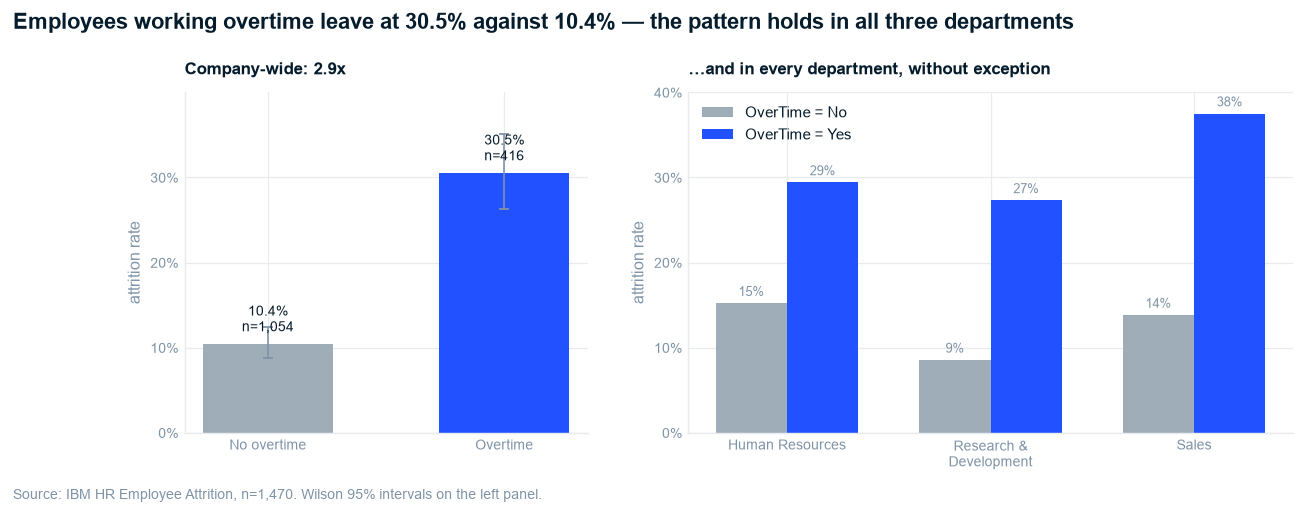

In [8]:
ot = rate_table("OverTime", order=["No", "Yes"])
print(ot.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1, 1.5]})
ax = axes[0]
ax.bar([0, 1], ot.rate, color=[GREY, LEAVER], width=.55)
ax.errorbar([0, 1], ot.rate, yerr=[ot.rate - ot.lo, ot.hi - ot.rate], fmt="none",
            ecolor=SLATE, elinewidth=.9, capsize=3)
for i, (r, n) in enumerate(zip(ot.rate, ot.n)):
    ax.annotate(f"{r:.1%}\nn={n:,}", xy=(i, r), xytext=(0, 7), textcoords="offset points",
                ha="center", fontsize=8, color=NAVY)
ax.set_xticks([0, 1]); ax.set_xticklabels(["No overtime", "Overtime"])
ax.set_ylim(0, .40); ax.set_yticks(np.arange(0, .36, .1))
ax.set_yticklabels([f"{v:.0%}" for v in np.arange(0, .36, .1)])
ax.set_ylabel("attrition rate"); ax.set_title("Company-wide: 2.9x", loc="left", fontsize=9.5)

ax = axes[1]
depts = sorted(df.Department.unique())
w = .35
for i, (v, col) in enumerate([("No", GREY), ("Yes", LEAVER)]):
    r = [y[(df.Department == d) & (df.OverTime == v)].mean() for d in depts]
    ax.bar(np.arange(len(depts)) + (i - .5) * w, r, width=w, color=col,
           label=f"OverTime = {v}")
    for j, val in enumerate(r):
        ax.annotate(f"{val:.0%}", xy=(j + (i - .5) * w, val), xytext=(0, 4),
                    textcoords="offset points", ha="center", fontsize=7, color=SLATE)
ax.set_xticks(range(len(depts)))
ax.set_xticklabels([d.replace(" & ", " &\n") for d in depts], fontsize=8)
ax.set_ylabel("attrition rate"); ax.legend(loc="upper left")
ax.set_yticks(np.arange(0, .41, .1)); ax.set_yticklabels([f"{v:.0%}" for v in np.arange(0, .41, .1)])
ax.set_title("…and in every department, without exception", loc="left", fontsize=9.5)

fig.suptitle("Employees working overtime leave at 30.5% against 10.4% — the pattern holds in all three departments",
             x=0.005, ha="left", fontsize=12, fontweight="bold", color=NAVY, y=1.06)
fig.text(0.005, -0.04, "Source: IBM HR Employee Attrition, n=1,470. Wilson 95% intervals on the left panel.",
         ha="left", fontsize=7.5, color=SLATE)
figsave(fig, "ex06_overtime")
plt.show()

**The composite flag that `DOCS` §7 proposes — tested, not assumed.**

In [9]:
hw = (df.OverTime == "Yes") & (df.WorkLifeBalance <= 2)
print(f"OverTime alone                  : {y[df.OverTime == 'Yes'].mean():.1%}  (n={int((df.OverTime=='Yes').sum()):,})")
print(f"HighWorkloadFlag (OT & WLB<=2)  : {y[hw].mean():.1%}  (n={int(hw.sum()):,})")
print(f"lift from adding the WLB term   : {(y[hw].mean() - y[df.OverTime == 'Yes'].mean())*100:+.1f} pp")
print("\n-> Adding WorkLifeBalance to the overtime flag buys ~3 pp while discarding two-thirds of")
print("   the exposed population. Consistent with WLB sitting inside the noise band (02 S2.1).")
print("   The composite is carried into Stage 4 as an ABLATION CANDIDATE, not as a given.")

OverTime alone                  : 30.5%  (n=416)
HighWorkloadFlag (OT & WLB<=2)  : 33.3%  (n=126)
lift from adding the WLB term   : +2.8 pp

-> Adding WorkLifeBalance to the overtime flag buys ~3 pp while discarding two-thirds of
   the exposed population. Consistent with WLB sitting inside the noise band (02 S2.1).
   The composite is carried into Stage 4 as an ABLATION CANDIDATE, not as a given.


> **So What:** overtime is the single clearest lever in the file — 2.9× the attrition rate,
> stable across all three departments, and defined by a fact the HRIS already records.
>
> **Implication:** it is also the one finding here whose *mechanism* is unidentifiable from a
> snapshot. Overtime may drive exits, or the people already heading for the door may be the ones
> given overtime. Stage 5a quantifies the association after adjustment; nothing in this project
> licenses the causal claim, and the report says so.

## 3.7 Branch B — where attrition concentrates by role

saved: ex07_role_ranking.png


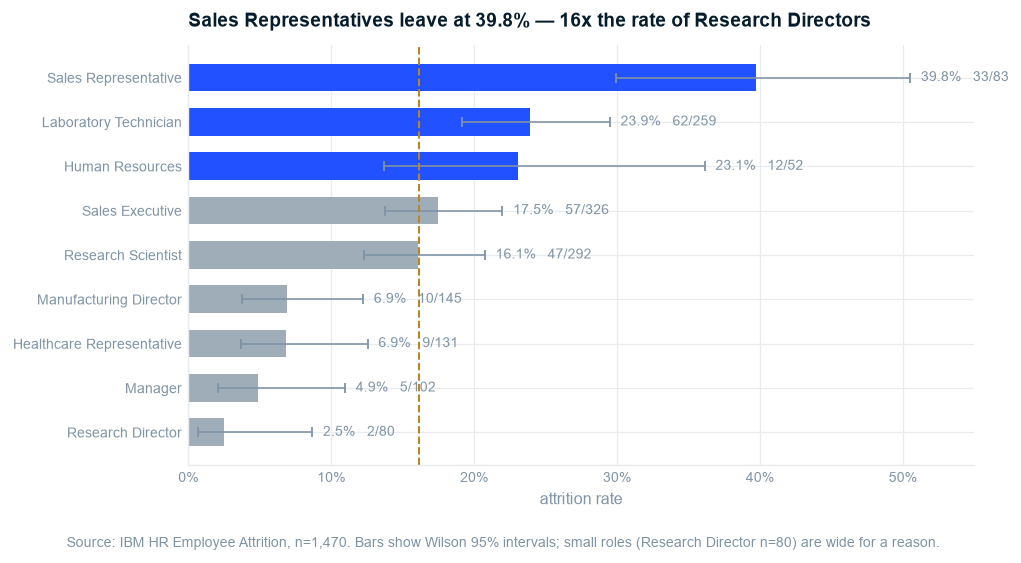

                           leavers    n   rate     lo     hi
JobRole                                                     
Research Director                2   80  0.025  0.007  0.087
Manager                          5  102  0.049  0.021  0.110
Healthcare Representative        9  131  0.069  0.037  0.125
Manufacturing Director          10  145  0.069  0.038  0.122
Research Scientist              47  292  0.161  0.123  0.207
Sales Executive                 57  326  0.175  0.137  0.220
Human Resources                 12   52  0.231  0.137  0.361
Laboratory Technician           62  259  0.239  0.191  0.295
Sales Representative            33   83  0.398  0.299  0.505


In [10]:
t_role = rate_table("JobRole").sort_values("rate")
fig, ax = plt.subplots(figsize=(7.8, 4.2))
yy = np.arange(len(t_role))
cols = [LEAVER if r >= .23 else GREY for r in t_role.rate]
ax.barh(yy, t_role.rate, color=cols, height=.62)
ax.errorbar(t_role.rate, yy, xerr=[t_role.rate - t_role.lo, t_role.hi - t_role.rate],
            fmt="none", ecolor=SLATE, elinewidth=.9, capsize=2.5)
ax.axvline(BASE, color=MARKER, ls="--", lw=1.1)
ax.annotate(f"company average {BASE:.1%}", xy=(BASE, -.9), xytext=(4, 0),
            textcoords="offset points", color=MARKER, fontsize=7.5)
ax.set_yticks(yy); ax.set_yticklabels(t_role.index, fontsize=8)
ax.set_xlabel("attrition rate"); ax.set_xlim(0, .55)
ax.set_xticks(np.arange(0, .51, .1)); ax.set_xticklabels([f"{v:.0%}" for v in np.arange(0, .51, .1)])
for i, (r, n, k) in enumerate(zip(t_role.rate, t_role.n, t_role.leavers)):
    ax.annotate(f"{r:.1%}   {k}/{n}", xy=(t_role.hi.iloc[i], i), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=7.5, color=SLATE)
ax.set_title("Sales Representatives leave at 39.8% — 16x the rate of Research Directors", loc="left")
fig.text(0.005, -0.04, "Source: IBM HR Employee Attrition, n=1,470. Bars show Wilson 95% intervals; "
                       "small roles (Research Director n=80) are wide for a reason.",
         ha="left", fontsize=7.5, color=SLATE)
figsave(fig, "ex07_role_ranking")
plt.show()
print(t_role.round(3).to_string())

> **So What:** three roles — Sales Representative, Laboratory Technician, Human Resources — run
> at or above 23% and account for a disproportionate share of exits. But the intervals matter: HR
> (n = 52) spans 13–37%, so it is *ranked* high without being *distinguishable* from the middle of
> the pack.
>
> **Implication:** target Sales Representatives (n = 83, interval 30–51%, entirely above the
> company average) with confidence. Treat the small-role rankings as a watchlist, not a finding.

## 3.8 Branch A — fixed traits, reported for targeting and fairness only

Nothing in this section is a lever. It is here because the fairness audit in `05_modeling` §5.6
needs it, and because one of these is going to drive model flags whether we like it or not.

In [11]:
for col in ["MaritalStatus", "Gender", "EducationField"]:
    t = rate_table(col).sort_values("rate", ascending=False)
    print(f"{col}:")
    print(t.round(3).to_string(), "\n")

ct = pd.crosstab(df.MaritalStatus, y)
chi2, p, dof, _ = stats.chi2_contingency(ct)
v = np.sqrt(chi2 / (len(df) * (min(ct.shape) - 1)))
print(f"MaritalStatus x Attrition: chi2 p = {p:.2e}, Cramer's V = {v:.3f}")
ct_g = pd.crosstab(df.Gender, y)
chi2g, pg, _, _ = stats.chi2_contingency(ct_g)
print(f"Gender        x Attrition: chi2 p = {pg:.3f}, Cramer's V = "
      f"{np.sqrt(chi2g / len(df)):.3f}  -> not distinguishable from chance")

MaritalStatus:
               leavers    n   rate     lo     hi
MaritalStatus                                   
Single             120  470  0.255  0.218  0.297
Married             84  673  0.125  0.102  0.152
Divorced            33  327  0.101  0.073  0.138 

Gender:
        leavers    n   rate     lo     hi
Gender                                   
Male        150  882  0.170  0.147  0.196
Female       87  588  0.148  0.122  0.179 

EducationField:
                  leavers    n   rate     lo     hi
EducationField                                     
Human Resources         7   27  0.259  0.132  0.447
Technical Degree       32  132  0.242  0.177  0.322
Marketing              35  159  0.220  0.163  0.291
Life Sciences          89  606  0.147  0.121  0.177
Medical                63  464  0.136  0.108  0.170
Other                  11   82  0.134  0.077  0.224 

MaritalStatus x Attrition: chi2 p = 9.46e-11, Cramer's V = 0.177
Gender        x Attrition: chi2 p = 0.291, Cramer's V = 0.028

> **So What:** single employees leave at 25.5% against 10.1% for divorced employees — a
> difference roughly as large as the overtime effect, and one HR cannot act on. Gender shows no
> detectable difference (p = 0.29).
>
> **Implication (and this is the uncomfortable one):** any well-calibrated risk model will
> therefore flag single employees at roughly twice the rate of married ones. That is statistically
> correct and it is a protected-adjacent targeting disparity. `05_modeling` §5.6 measures it and
> measures the accuracy cost of excluding the field, rather than leaving the trade-off implicit.

## 3.9 Branch F — the engagement fields, shown as ordinal data

`DOCS` §5: Likert scales should not be averaged as if interval without checking the shape first.
Diverging stacked bars preserve the categorical meaning. This also decides the encoding —
`JobSatisfaction`, `RelationshipSatisfaction` and `WorkLifeBalance` were **non-monotonic** in
`02_cleaning` §2.3.

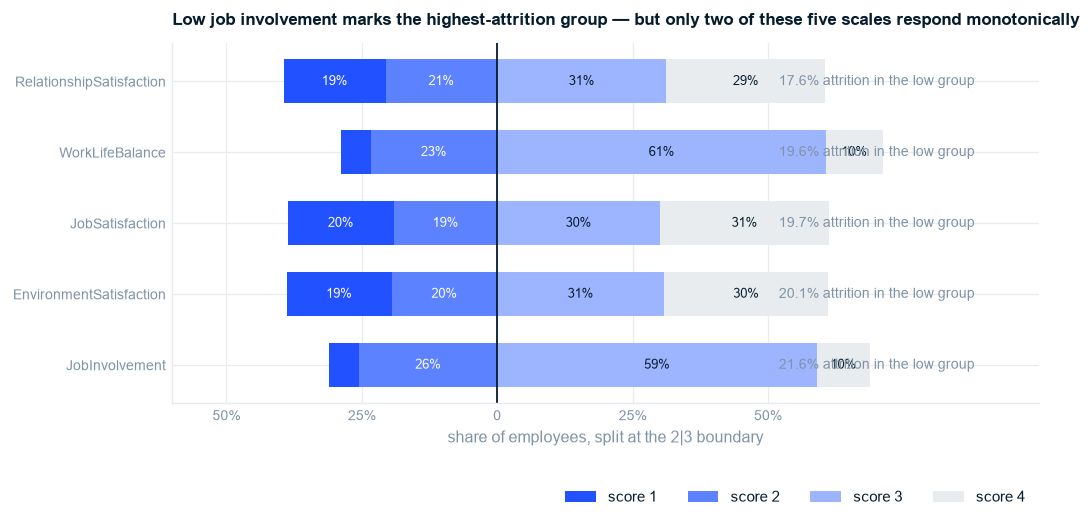

Monotonic response (attrition falls with every step up)?
  JobInvolvement             [0.337 0.189 0.144 0.09 ]  yes
  EnvironmentSatisfaction    [0.254 0.15  0.137 0.135]  yes
  JobSatisfaction            [0.228 0.164 0.165 0.113]  NO
  WorkLifeBalance            [0.312 0.169 0.142 0.176]  NO
  RelationshipSatisfaction   [0.207 0.149 0.155 0.148]  NO


In [12]:
LIKERT = ["JobInvolvement", "EnvironmentSatisfaction", "JobSatisfaction",
          "WorkLifeBalance", "RelationshipSatisfaction"]
fig, ax = plt.subplots(figsize=(8.6, 3.6))
h, ypos = .62, np.arange(len(LIKERT))
shades = [LEAVER, "#5C82FF", "#9DB4FF", GRID]
for i, c in enumerate(LIKERT):
    share = df[c].value_counts(normalize=True).sort_index()
    left = -(share.get(1, 0) + share.get(2, 0))
    for lvl, col in zip([1, 2, 3, 4], shades):
        wdt = share.get(lvl, 0)
        ax.barh(i, wdt, left=left, height=h, color=col,
                label=f"score {lvl}" if i == 0 else None)
        if wdt > .07:
            ax.annotate(f"{wdt:.0%}", xy=(left + wdt / 2, i), ha="center", va="center",
                        fontsize=7, color="white" if lvl <= 2 else NAVY)
        left += wdt
ax.axvline(0, color=NAVY, lw=1)
rates = {c: y[df[c] <= 2].mean() for c in LIKERT}
for i, c in enumerate(LIKERT):
    ax.annotate(f"{rates[c]:.1%} attrition in the low group", xy=(.52, i), fontsize=7.5,
                va="center", color=SLATE)
ax.set_yticks(ypos); ax.set_yticklabels(LIKERT, fontsize=8)
ax.set_xlim(-.6, 1.0); ax.set_xticks([-.5, -.25, 0, .25, .5])
ax.set_xticklabels(["50%", "25%", "0", "25%", "50%"])
ax.set_xlabel("share of employees, split at the 2|3 boundary")
ax.legend(loc="lower right", ncol=4, bbox_to_anchor=(1, -.32))
ax.set_title("Low job involvement marks the highest-attrition group — but only two of these five scales respond monotonically",
             loc="left", fontsize=9.5)
plt.show()

print("Monotonic response (attrition falls with every step up)?")
for c in LIKERT:
    r = df.groupby(c).Attrition_flag.mean().to_numpy()
    print(f"  {c:<26} {np.round(r,3)}  {'yes' if np.all(np.diff(r) <= 0) else 'NO'}")

> **So What:** `JobInvolvement` separates cleanly (33.7% → 9.0%); `WorkLifeBalance` does not, and
> sits inside the noise band established in `02_cleaning` §2.1.
>
> **Implication:** these five fields are quarantined into Scope 2 regardless of how well they
> perform, because `DOCS` §3B cannot rule out that they were captured on the way out. The value of
> quarantining is measured in `05_modeling` §5.4, not argued.

## 3.10 Branch D — the commute question, asked properly

`DOCS` §5 proposes distance × role as a headline cut. It sits just above the noise band (AUC 0.562),
so the honest treatment is to show it at the resolution where it either appears or doesn't.

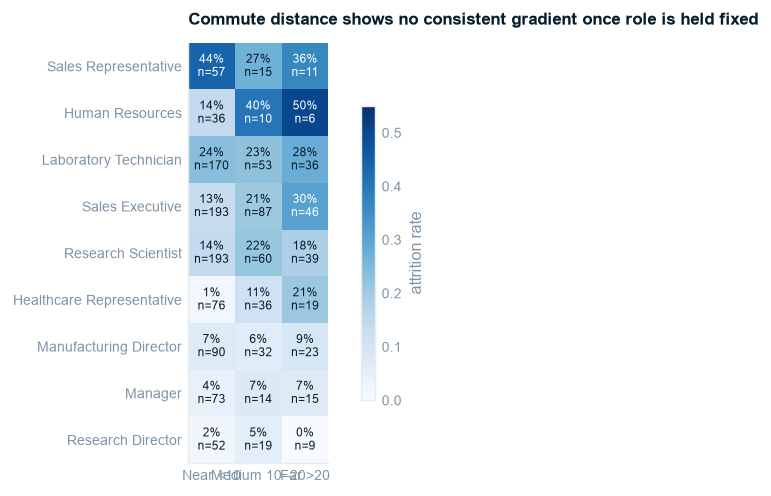

Attrition rate by distance band (all roles pooled):
               leavers    n   rate     lo     hi
distance_band                                   
Near <10           133  940  0.141  0.121  0.165
Medium 10–20        59  326  0.181  0.143  0.226
Far >20             45  204  0.221  0.169  0.282

Spearman(DistanceFromHome, attrition): rho = +0.079, p = 0.0024


In [13]:
dist_band = pd.cut(df.DistanceFromHome, [0, 9, 20, 30], labels=["Near <10", "Medium 10–20", "Far >20"])
piv = pd.crosstab(df.JobRole, dist_band, values=y, aggfunc="mean")
cnt = pd.crosstab(df.JobRole, dist_band)
order = piv.mean(axis=1).sort_values(ascending=False).index
piv, cnt = piv.loc[order], cnt.loc[order]

fig, ax = plt.subplots(figsize=(6.4, 4.2))
im = ax.imshow(piv, cmap="Blues", vmin=0, vmax=.55)
ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels(piv.columns, fontsize=8)
ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels(piv.index, fontsize=8)
ax.grid(False)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v, n = piv.iloc[i, j], cnt.iloc[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.0%}\nn={n}", ha="center", va="center", fontsize=6.5,
                    color="white" if v > .3 else NAVY)
ax.set_title("Commute distance shows no consistent gradient once role is held fixed", loc="left",
             fontsize=9.5)
fig.colorbar(im, ax=ax, shrink=.7, label="attrition rate")
plt.show()

print("Attrition rate by distance band (all roles pooled):")
print(rate_table(dist_band.rename("distance_band")).round(3).to_string())
print("\nSpearman(DistanceFromHome, attrition):",
      f"rho = {stats.spearmanr(df.DistanceFromHome, y).statistic:+.3f}, "
      f"p = {stats.spearmanr(df.DistanceFromHome, y).pvalue:.4f}")

> **So What:** pooled across roles there is a real but small gradient (14.1% near → 22.1% far);
> split by role it dissolves into cells of 5–30 employees with no consistent direction.
>
> **Implication:** commute distance is reported as a **marginal** finding with its interval, not as
> a driver. It clears the noise floor by a hair and is the one feature in this project whose verdict
> genuinely depends on how the question is asked — which is why the exhibit shows both views.

## 3.11 Ghost deck — revised after seeing the data

STRUCTURE.md §3 requires the storyboard be updated once the data has spoken. Three changes:

In [14]:
revisions = pd.DataFrame([
    {"exhibit": "EX 3", "planned": "WLB and commute distance fall inside the noise band",
     "revised": "CONFIRMED for WorkLifeBalance (0.536, inside). Commute distance clears marginally "
                "(0.562) and is downgraded to 'marginal', not 'inert' - it gets its own caveat"},
    {"exhibit": "EX 5", "planned": "Attrition is a first-two-years and first-level problem",
     "revised": "CONFIRMED and sharpened - 60% of leavers are Level 1, 68% have <=5 years"},
    {"exhibit": "EX 6", "planned": "Overtime doubles attrition in every department",
     "revised": "CONFIRMED - 2.9x, not 2x, and holds in all three departments"},
    {"exhibit": "EX 4", "planned": "The 38% pay gap is a job-level effect",
     "revised": "CONFIRMED and stronger than expected - the gap reverses sign at Levels 2 and 5"},
    {"exhibit": "NEW", "planned": "-",
     "revised": "MaritalStatus promoted from a demographic footnote to a fairness finding: "
                "25.5% vs 10.1% is overtime-sized, unactionable, and will drive model flags"},
])
print(revisions.to_string(index=False, max_colwidth=95))

exhibit                                                planned                                                                                         revised
   EX 3    WLB and commute distance fall inside the noise band CONFIRMED for WorkLifeBalance (0.536, inside). Commute distance clears marginally (0.562) an...
   EX 5 Attrition is a first-two-years and first-level problem                        CONFIRMED and sharpened - 60% of leavers are Level 1, 68% have <=5 years
   EX 6         Overtime doubles attrition in every department                                    CONFIRMED - 2.9x, not 2x, and holds in all three departments
   EX 4                  The 38% pay gap is a job-level effect                  CONFIRMED and stronger than expected - the gap reverses sign at Levels 2 and 5
    NEW                                                      - MaritalStatus promoted from a demographic footnote to a fairness finding: 25.5% vs 10.1% is ...


---

## Stage 3 — Gate Checklist (`DOCS/STRUCTURE.md`)

- [x] **Automated profiling generated and reviewed** — manual equivalent (§3.1); `ydata-profiling`
      deliberately not a dependency so a clone runs on the pinned requirements
- [x] **Each Stage 0 hypothesis has a corresponding analysis** — branches A (§3.8), B (§3.4, §3.7),
      C (§3.5), D (§3.6, §3.10), E (§3.4), F (§3.9), Z (§3.3)
- [x] **Key distributions and relationships visualised and annotated**
- [x] **All chart titles are Action Titles** — every title states the insight
- [x] **Every finding has a "So What" and "Implication"**
- [x] **Ghost deck updated** — §3.11, five revisions logged
- [x] **Data issues discovered during EDA logged** — none new; the §2.4 collinearity register was
      confirmed visually in §3.3 and drives the Stage 5a specification
- [x] **Preliminary findings documented**

### Exhibits banked for the report

| File | Serves |
|---|---|
| `ex04_pay_confound.png` | Key Line 2 — pay is not the lever |
| `ex05_tenure_level.png` | Key Line 2 — where attrition concentrates |
| `ex06_overtime.png` | Key Line 2 — the clearest lever |
| `ex07_role_ranking.png` | Key Line 2 — role targeting, with intervals |

**Next:** `04_diagnostic.ipynb` — the noise floor, and a verdict for every branch.